# 05 · LoRA v2 e placar final

Guiding Hand · Generative AI for Engineering

**Por que um v2?** No notebook 04, o LoRA v1 praticamente empatou com o RAG simples. Diagnóstico: o alvo de treino do v1 era um resumo extrativo que copiava o *início* do trecho. Em trechos longos o dado pedido ficava de fora (ex.: o alvo do trecho de estacionamento terminava antes do "2%"), e o modelo aprendeu a copiar o começo em vez de responder à pergunta.

**Correção (v2):** mesmas 136 situações de treino, mesmos 8 trechos reservados, mesma configuração de treino, mas com **respostas-alvo diretas e curtas, escritas à mão e conferidas contra o trecho** (`src/respostas_treino.py`). Só o alvo mudou.

Antes: `python src/gerar_dados_treino.py v2` e `python src/treinar_lora.py v2` (feche os outros notebooks que usam a GPU).

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))
import numpy as np, pandas as pd, torch
pd.set_option('display.width', 230); pd.set_option('display.max_colwidth', 70)
import matplotlib.pyplot as plt
from config import CASOS, RESULTADOS, RAIZ, carregar_limiar
from busca import Buscador, carregar_trechos
from geracao import LLM, responder_rag
from avaliacao import placar

LIMIAR = carregar_limiar()
trechos = carregar_trechos()
casos = [json.loads(l) for l in open(CASOS, encoding='utf-8')]
buscador = Buscador(trechos)
ADAPTADOR = RAIZ / 'modelo-lora_v2'
assert ADAPTADOR.exists(), 'Rode antes: python src/treinar_lora.py v2'
llm = LLM(adaptador=str(ADAPTADOR))
print('limiar =', LIMIAR, '| VRAM (GB):', round(torch.cuda.memory_allocated() / 1e9, 2))

W1110 23:14:56.952000 19176 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
W1110 23:15:01.515000 19176 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

limiar = 0.8754 | VRAM (GB): 3.1


## 1. Treino do v2

v1: 136 exemplos | perda por época [0.0328, 0.0031, 0.0013] | 626s | VRAM pico 1.71 GB
v2: 136 exemplos | perda por época [0.1809, 0.0531, 0.0141] | 624s | VRAM pico 1.6 GB


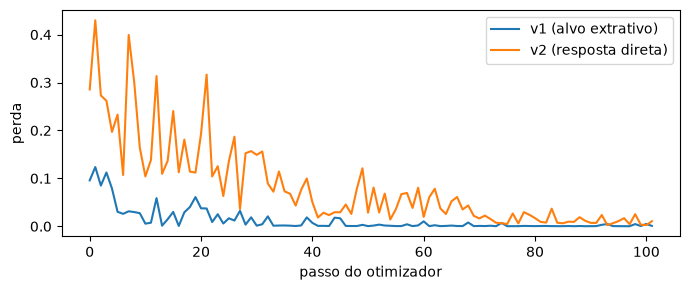

In [2]:
log1 = json.loads((RESULTADOS / 'treino_log.json').read_text(encoding='utf-8'))
log2 = json.loads((RESULTADOS / 'treino_log_v2.json').read_text(encoding='utf-8'))
for nome, l in [('v1', log1), ('v2', log2)]:
    print(f"{nome}: {l['n_exemplos']} exemplos | perda por época {l['perda_por_epoca']} | {l['segundos']}s | VRAM pico {l['vram_pico_gb']} GB")
(RAIZ / 'avaliacao' / 'figuras').mkdir(exist_ok=True)
plt.figure(figsize=(7, 3)); plt.plot(log1['perda_por_passo'], label='v1 (alvo extrativo)'); plt.plot(log2['perda_por_passo'], label='v2 (resposta direta)')
plt.xlabel('passo do otimizador'); plt.ylabel('perda'); plt.legend(); plt.tight_layout()
plt.savefig(RAIZ / 'avaliacao' / 'figuras' / 'loss_v1_v2.png', dpi=150); plt.show()

## 2. Rodar a config C2 (LoRA v2) nos 35 casos

In [3]:
configs = {
    'C2 (RAG + LoRA v2 + limiar)': lambda p: responder_rag(llm, buscador, p, limiar=LIMIAR),
    'C2 sem limiar': lambda p: responder_rag(llm, buscador, p, limiar=None),
}
novos = {}
for nome, fn in configs.items():
    t0 = time.time(); novos[nome] = {c['id']: fn(c['pergunta']) for c in casos}
    arq = RESULTADOS / (nome.split(' (')[0].replace(' ', '_') + '.json')
    arq.write_text(json.dumps(novos[nome], ensure_ascii=False, indent=1), encoding='utf-8')
    print(f'{nome}: {time.time() - t0:.0f}s -> {arq.name}')

C2 (RAG + LoRA v2 + limiar): 182s -> C2.json
C2 sem limiar: 216s -> C2_sem_limiar.json


## 3. Placar final (7 configurações)
- **A**: sem contexto · **B**: RAG simples · **C**: RAG + LoRA v1 · **C2**: RAG + LoRA v2
- "sem limiar" = sem o filtro de similaridade (o modelo é quem decide recusar)

In [4]:
def carregar(arq): return json.loads((RESULTADOS / arq).read_text(encoding='utf-8'))
todos = {'A (sem contexto)': carregar('A.json'), 'B (RAG + limiar)': carregar('B.json'), 'B sem limiar': carregar('B_sem_limiar.json'),
         'C (RAG + LoRA v1 + limiar)': carregar('C.json'), 'C sem limiar': carregar('C_sem_limiar.json'), **novos}
tab, detalhes = placar(todos, casos, trechos)
print(tab.T.to_string())
tab.to_csv(RAIZ / 'avaliacao' / 'placar_final.csv')

config                A (sem contexto) B (RAG + limiar) B sem limiar C (RAG + LoRA v1 + limiar) C sem limiar C2 (RAG + LoRA v2 + limiar) C2 sem limiar
acerto (/27)                         7               19           20                         20           21                          23            24
citação correta (/27)                0               21           22                         21           22                          22            23
recusa correta (/8)                  2                8            5                          8            7                           8             7
recusa indevida (/27)                0                1            0                          1            0                           1             0
JSON válido (/35)                   33               34           34                         34           34                          35            35
alucinação (/35)                    31                0            3                          

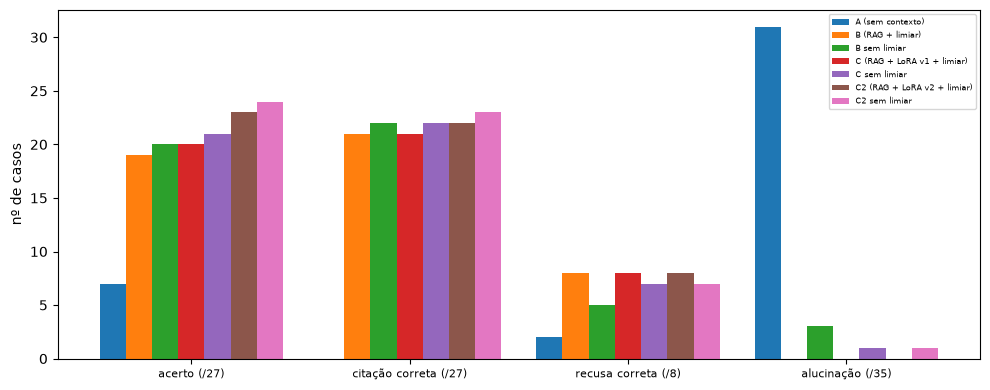

In [5]:
nomes = list(tab.columns[[0, 1, 2, 5]])
x = np.arange(len(nomes)); larg = 0.12
plt.figure(figsize=(10, 4))
for i, cfg in enumerate(tab.index):
    plt.bar(x + (i - 3) * larg, [tab.loc[cfg, n] for n in nomes], larg, label=cfg)
plt.xticks(x, nomes, fontsize=8); plt.ylabel('nº de casos'); plt.legend(fontsize=6); plt.tight_layout()
plt.savefig(RAIZ / 'avaliacao' / 'figuras' / 'placar_final.png', dpi=150); plt.show()

## 4. Aprendeu o comportamento ou decorou a base?
Trechos **NAO visto** nunca apareceram no treino (nem como resposta, nem como contexto).

In [6]:
fora = set(log2['trechos_fora_do_treino'])
grupo = {c['id']: ('NAO visto' if c['trecho_esperado'] in fora else 'visto') for c in casos if c['tipo'] == 'resposta'}
print('casos -> visto:', sum(v == 'visto' for v in grupo.values()), '| NAO visto:', sum(v == 'NAO visto' for v in grupo.values()))
linhas = []
for nome, det in detalhes.items():
    d = det[det.tipo == 'resposta'].copy(); d['grupo'] = d.id.map(grupo)
    for g, sub in d.groupby('grupo'):
        linhas.append({'config': nome, 'grupo': g, 'acerto': int(sub.acerto.sum()), 'citação correta': int(sub.citacao_correta.sum())})
print(pd.DataFrame(linhas).pivot(index='config', columns='grupo', values=['acerto', 'citação correta']).to_string())

casos -> visto: 19 | NAO visto: 8
                               acerto       citação correta      
grupo                       NAO visto visto       NAO visto visto
config                                                           
A (sem contexto)                    2     5               0     0
B (RAG + limiar)                    5    14               7    14
B sem limiar                        5    15               7    15
C (RAG + LoRA v1 + limiar)          7    13               6    15
C sem limiar                        7    14               6    16
C2 (RAG + LoRA v2 + limiar)         7    16               8    14
C2 sem limiar                       7    17               8    15


## 5. O erro do v1 foi corrigido? Q12 (percentual de vagas) em cada configuração

In [7]:
for nome in ['B (RAG + limiar)', 'C (RAG + LoRA v1 + limiar)', 'C2 (RAG + LoRA v2 + limiar)']:
    r = todos[nome]['Q12']
    print(nome, '->', (r['raw'] or str(r['saida']))[:260]); print()

B (RAG + limiar) -> {"resposta":"Deve ser reservado 2% (dois por cento) do total de vagas de estacionamento, garantindo, no mínimo, uma vaga sinalizada e conforme normas de acessibilidade.","fonte":"Lei 13.146/2015, art. 47, caput e § 1º","status":"ok"}

C (RAG + LoRA v1 + limiar) -> {"resposta":"Em todas as áreas de estacionamento aberto ao público, de uso público ou privado de uso coletivo e em vias públicas, devem ser reservadas vagas próximas aos acessos de circulação de pedestres, devidamente sinalizadas, para veículos que transportem

C2 (RAG + LoRA v2 + limiar) -> {"resposta":"Em todas as áreas de estacionamento abertos ao público, de uso público ou privado de uso coletivo e em vias públicas, devem ser reservados 2% do total, garantida no mínimo 1 vaga devidamente sinalizada.","fonte":"Lei 13.146/2015, art. 47, caput e 



## 6. Casos em que o C2 ainda errou

In [8]:
det = detalhes['C2 (RAG + LoRA v2 + limiar)']
errados = det[((det.tipo == 'resposta') & ~(det.acerto & det.citacao_correta)) | ((det.tipo == 'nao_consta') & ~det.recusa_correta)]
for id_ in errados.id:
    c = next(x for x in casos if x['id'] == id_)
    r = todos['C2 (RAG + LoRA v2 + limiar)'][id_]
    print(id_, c['tipo'], '|', c['pergunta'])
    print('   esperado:', c['fonte_esperada'] or 'nao_consta', '| trechos buscados:', r['trechos'], '| top1:', round(r['top_score'], 3))
    print('   saída:', (r['raw'] or str(r['saida']))[:240]); print()

Q02 resposta | O que significa acessibilidade segundo a Lei Brasileira de Inclusão?
   esperado: Lei 13.146/2015, art. 3º, I | trechos buscados: ['T17', 'T11', 'T21'] | top1: 0.902
   saída: {"resposta":"Acessibilidade é direito que garante à pessoa com deficiência ou com mobilidade reduzida viver de forma independente e exercer seus direitos de cidadania e de participação social.","fonte":"Lei 13.146/2015, art. 53","status":"o

Q04 resposta | O que são barreiras urbanísticas?
   esperado: Lei 13.146/2015, art. 3º, IV, a e c | trechos buscados: ['T04', 'T27', 'T28'] | top1: 0.848
   saída: {'resposta': 'Não consta na base de conhecimento.', 'fonte': None, 'status': 'nao_consta'}

Q05 resposta | Recusar uma adaptação razoável conta como discriminação?
   esperado: Lei 13.146/2015, art. 4º, caput e § 1º | trechos buscados: ['T05', 'T22', 'T11'] | top1: 0.884
   saída: {"resposta":"Sim. Praticar, induzir ou incitar discriminação em razão da deficiência implica recusar adaptações razoáveis

## 7. Interpretação (preencher depois de rodar)

- **v1 × v2:** _o v2 corrigiu o problema de respostas que não respondem (ex.: Q12)? O que mudou no acerto?_
- **Com × sem limiar:** _o LoRA recusa sozinho (sem limiar) melhor que o B? Quantos "não consta" ele acertou?_
- **Visto × não visto:** _o ganho aparece nos trechos nunca vistos?_
- **Limites:** _os erros que sobraram são de busca ou de geração? (alimenta o relatório dos 5 erros)_
- **Ressalva:** n = 27 respostas e 8 "não consta": diferenças de 1 ou 2 casos não são conclusivas.